# Financial Fraud Detection Using ANN with Imbalanced Learning
A reproducible experiment notebook using the same pipeline and saved outputs as the API, dashboard and paper. IEEE-CIS results are empirical; synthetic data is limited to software tests. Do not treat development samples as full-dataset findings.

In [1]:
from pathlib import Path
import sys, json, uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / "ml").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "ml").is_dir(), "Run from the project root or notebooks directory"
sys.path.insert(0, str(ROOT))
from ml.config import ExperimentConfig
from ml.data import verify, load_dataset, split_data
from ml.preprocessing import Preprocessor
from ml.evaluation import metrics, choose_threshold
from ml.pipeline import run
from backend.store import Store
from backend.worker import execute
from scripts.run_experiments import FEATURES
RUN_NEW_EXPERIMENTS = False
DATASET = "ieee-cis"
MAX_ROWS = 0


## Acquisition and integrity
If files are absent, run the official acquisition script. Authenticate with the current Kaggle CLI and accept competition rules directly on Kaggle. Credentials are never printed. This cell records the supplied raw training files and validates keys/target/schema.

In [2]:
raw = ROOT / "data/raw/ieee-cis"
if not all((raw / n).exists() for n in ["train_transaction.csv", "train_identity.csv"]):
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts/download_dataset.py")], check=True)
manifest = verify(raw)
pd.DataFrame({k:v for k,v in manifest.items() if k.startswith("train_")}).T


,rows,columns,bytes,sha256
train_transaction.csv,590540,394,683351067,3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a...
train_identity.csv,144233,41,26529680,b63c725d8377be90a995268d97f347c17d456b95db4580...


## Exploratory analysis and class imbalance
The aggregate snapshot excludes raw transaction details. Rows are after documented exact-covariate duplicate removal. Relative transaction time is not a calendar timestamp.

,rows,columns,fraud_count,prevalence,duplicates_removed
0,590053,434,20654,0.035004,487


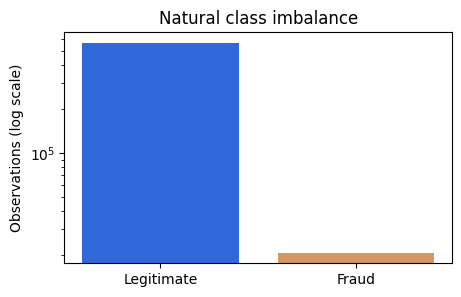

,name,type,missing,unique
417,id_24,categorical,585306,12
418,id_25,categorical,584921,341
400,id_07,numeric,584898,84
401,id_08,numeric,584898,94
414,id_21,categorical,584894,490
419,id_26,categorical,584890,95
420,id_27,categorical,584884,2
416,id_23,categorical,584884,3
415,id_22,categorical,584884,25
14,dist2,numeric,552426,1751


In [3]:
snapshot = ROOT / "data/processed/summary-ieee-cis.json"
if snapshot.exists():
    summary = json.loads(snapshot.read_text())
else:
    from ml.data import summary as summarize
    summary = summarize(ROOT, DATASET)
display(pd.DataFrame([{k:summary[k] for k in ["rows","columns","fraud_count","prevalence","duplicates_removed"]}]))
plt.figure(figsize=(5,3))
plt.bar(["Legitimate","Fraud"], [summary["rows"]-summary["fraud_count"],summary["fraud_count"]],color=["#3067d9","#d79963"])
plt.yscale("log");plt.ylabel("Observations (log scale)");plt.title("Natural class imbalance");plt.show()
schema = pd.DataFrame(summary["features"])
display(schema[["name","type","missing","unique"]].sort_values("missing",ascending=False).head(20))


## User-supplied notebook references
See docs/REFERENCE_NOTEBOOK_REVIEW.md. The XGB notebook uses train/test-concatenated aggregates and label-informed UID post-processing; these are not part of this inductive ANN protocol. The EDA notebook overwrites TimeSeriesSplit with KFold. Relative transaction time is retained without an invented calendar origin. Inspired EDA checks below use aggregate snapshots only.

In [ ]:
features=pd.DataFrame(summary["features"])
fig,axes=plt.subplots(1,2,figsize=(11,3))
missing=features.sort_values("missing",ascending=False).head(12)
axes[0].barh(missing.name,missing.missing/summary["rows"],color="#3067d9")
axes[0].set(xlabel="Missing fraction",title="Missingness patterns")
relative=next(f for f in summary["features"] if f["name"]=="TransactionDT")
axes[1].bar(range(len(relative["distribution"])),[v["count"] for v in relative["distribution"]],color="#16a393")
axes[1].set(xlabel="Relative-time bins",ylabel="Transactions",title="Relative transaction time (no calendar origin)")
plt.tight_layout();plt.show()


## Preprocessing and shared splits
All transforms fit the training partition only. SMOTENC operates on scaled numbers and categorical codes before one-hot encoding. Validation/test are never resampled. The notebook imports the actual implementation, preventing divergence from the application.

In [4]:
protocol = ExperimentConfig(dataset=DATASET, max_rows=MAX_ROWS, features=FEATURES)
print(protocol.model_dump_json(indent=2))
# The optional training path uses load_dataset, split_data and Preprocessor through run().
# Partition IDs/hashes are inspected below from each completed artifact.


{
  "name": "ANN experiment",
  "dataset": "ieee-cis",
  "expected_fingerprint": null,
  "method": "baseline",
  "hidden_layers": [
    64,
    32
  ],
  "activation": "relu",
  "dropout": [
    0.2,
    0.1
  ],
  "batch_norm": false,
  "l1": 0.0,
  "l2": 0.0001,
  "optimizer": "adam",
  "learning_rate": 0.001,
  "batch_size": 256,
  "epochs": 15,
  "patience": 5,
  "early_stopping": true,
  "scheduler": "plateau",
  "gradient_clip": 5.0,
  "checkpoint_metric": "average_precision",
  "loss": "binary_cross_entropy",
  "output": "sigmoid",
  "seed": 42,
  "split_seed": 2026,
  "split": "temporal",
  "validation_fraction": 0.15,
  "test_fraction": 0.15,
  "max_rows": 0,
  "fraud_weight": 20.0,
  "legitimate_weight": 1.0,
  "smote_strategy": "auto",
  "sampling_ratio": 0.3,
  "neighbors": 5,
  "threshold": 0.5,
  "optimize_threshold": true,
  "selection_metric": "f1",
  "features": [
    "TransactionAmt",
    "ProductCD",
    "card4",
    "card6",
    "addr2",
    "dist1",
    "dist2",
  

## Baseline ANN
Unweighted BCE, configurable hidden layers/dropout/regularization, optimizer, scheduler, early stopping and checkpoint. New training is an explicit option; each run obtains a new ID.

In [5]:
def train_method(method):
    config = protocol.model_copy(update={"method":method, "name":f"Notebook {method}"})
    config = ExperimentConfig.model_validate(config.model_dump())
    store = Store(ROOT)
    job = store.create(config)
    store.update(job["id"], "running")
    execute(store, store.get(job["id"]))
    assert store.get(job["id"])["status"] == "completed", store.get(job["id"])["error"]
    return job["id"]
if RUN_NEW_EXPERIMENTS:
    baseline_id = train_method("baseline")


## SMOTENC + ANN
Training-only oversampling uses configurable fraud/legitimate ratio and neighbors. Category-aware interpolation avoids treating arbitrary category codes as continuous coordinates.

In [6]:
if RUN_NEW_EXPERIMENTS:
    smote_id = train_method("smote")


## Cost-sensitive ANN
Weighted BCE applies separate positive class weights. A larger fraud weight is not automatically better. This method is independent of SMOTENC.

In [7]:
if RUN_NEW_EXPERIMENTS:
    weighted_id = train_method("cost_sensitive")


## Load genuine canonical outputs
Select the latest completed compatible full-data group when available. Never mix development, synthetic, or incompatible held-out observations. Later results can be exported with scripts/generate_paper_tables.py.

In [8]:
records = [json.loads(p.read_text()) for p in (ROOT/"artifacts").glob("*/result.json")]
real = [r for r in records if not r["dataset"]["demonstration"] and r["configuration"].get("run_role","primary")=="primary"]
assert real, "No IEEE-CIS results. Run the experiments before evaluating."
full = [r for r in real if not r["dataset"]["development_sample"]]
pool = full or real
latest = max(pool,key=lambda r:(ROOT/"artifacts"/r["id"]/"result.json").stat().st_mtime)
runs = [r for r in pool if r["split_hash"]==latest["split_hash"] and r["dataset"]["fingerprint"]==latest["dataset"]["fingerprint"]]
assert len({r["split_hash"] for r in runs})==1
ids = [json.loads((ROOT/"artifacts"/r["id"]/"splits.json").read_text()) for r in runs]
assert all(value==ids[0] for value in ids)
assert not set(ids[0]["train"]) & set(ids[0]["test"])
display(pd.DataFrame([{"id":r["id"],"method":r["configuration"]["method"],"seed":r["configuration"]["seed"],"development":r["dataset"]["development_sample"],**{k:v for k,v in r["metrics"].items() if k!="confusion_matrix"}} for r in runs]))


,id,method,seed,development,accuracy,precision,recall,f1,roc_auc,average_precision,...,tn,fp,fn,tp,flagged,transactions,prevalence,threshold,training_seconds,inference_seconds
0,12660dcb926246bc8575394718325b46,cost_sensitive,42,False,0.955258,0.362865,0.374150,0.368421,0.849707,0.364263,...,83393,2028,1932,1155,3183,88508,0.034878,0.81,122.051311,0.018172
1,4c54c7659f7e4d9dac679c2c2d1ea7bb,baseline,43,False,0.962625,0.455853,0.369615,0.408229,0.847058,0.380835,...,84059,1362,1946,1141,2503,88508,0.034878,0.18,196.597130,0.140095
2,ac2d51e385ed4d38bf1d766797fba69c,baseline,42,False,0.961664,0.443709,0.390671,0.415504,0.850679,0.397630,...,83909,1512,1881,1206,2718,88508,0.034878,0.13,134.140267,0.014585
3,c8160093f9094b76be1b13ccb5d15aef,smote,42,False,0.961043,0.442862,0.453191,0.447967,0.860352,0.431389,...,83661,1760,1688,1399,3159,88508,0.034878,0.59,161.203363,0.015337
4,ce040fc4d9384b02b6132f2f0876f88c,smote,43,False,0.963065,0.467195,0.419825,0.442245,0.857797,0.429589,...,83943,1478,1791,1296,2774,88508,0.034878,0.63,173.118190,0.015241


## Metric verification and validation-only threshold selection
Recompute metrics from saved probabilities and verify the same AP as the dashboard and paper. Threshold optimization never receives final-test probabilities.

In [9]:
for r in runs:
    with np.load(ROOT/"artifacts"/r["id"]/"predictions.npz") as data:
        config = ExperimentConfig.model_validate(r["configuration"])
        threshold = choose_threshold(data["validation_y"],data["validation_probability"],config)
        assert abs(threshold-r["selected_threshold"])<1e-12
        m = metrics(data["test_y"],data["test_probability"],threshold)
        assert abs(m["average_precision"]-r["metrics"]["average_precision"])<1e-12
print("Saved metrics and validation-selected thresholds verified")


Saved metrics and validation-selected thresholds verified


## Confusion matrices, ROC and precision-recall
Ranking curves use probabilities, not hard class decisions. AP is average precision, not trapezoidal integration of the compressed display points.

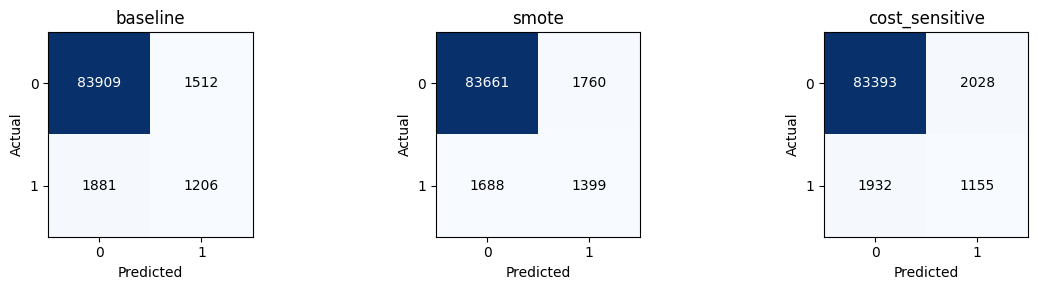

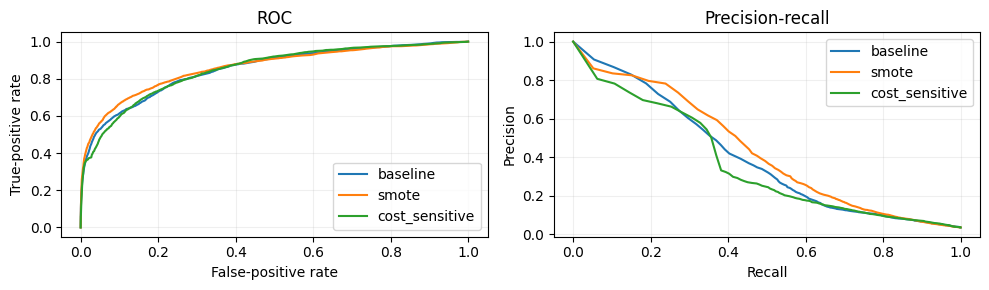

In [10]:
selected = [min([r for r in runs if r["configuration"]["method"]==m],key=lambda r:r["configuration"]["seed"]) for m in ["baseline","smote","cost_sensitive"]]
fig,axes = plt.subplots(1,3,figsize=(12,3))
for ax,r in zip(axes,selected):
    matrix=np.asarray(r["metrics"]["confusion_matrix"])
    ax.imshow(matrix,cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(matrix[i,j]),ha="center",va="center",color="white" if matrix[i,j]>matrix.max()/2 else "black")
    ax.set(xticks=[0,1],yticks=[0,1],xlabel="Predicted",ylabel="Actual",title=r["configuration"]["method"])
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3))
for r in selected:
    for ax,kind in zip(axes,["roc","pr"]):
        points=r["curves"][kind]
        ax.plot([p["x"] for p in points],[p["y"] for p in points],label=r["configuration"]["method"])
axes[0].set(xlabel="False-positive rate",ylabel="True-positive rate",title="ROC")
axes[1].set(xlabel="Recall",ylabel="Precision",title="Precision-recall")
for ax in axes:ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()


## Training history and timings
Training time excludes preprocessing/resampling. Model inference timing uses transformed matrices, not HTTP latency. Early stopping and checkpoint epochs are retained.

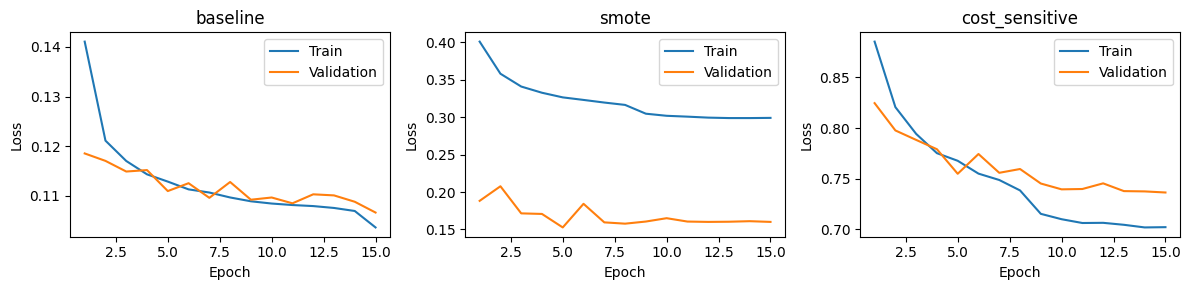

,method,seed,checkpoint_epoch,training_seconds,inference_seconds,total_seconds
0,cost_sensitive,42,15,122.051311,0.018172,177.360561
1,baseline,43,12,196.597130,0.140095,264.034219
2,baseline,42,15,134.140267,0.014585,191.882244
3,smote,42,13,161.203363,0.015337,239.263751
4,smote,43,15,173.118190,0.015241,267.000943


In [11]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,r in zip(axes,selected):
    history=pd.DataFrame(r["history"])
    ax.plot(history.epoch,history.train_loss,label="Train")
    ax.plot(history.epoch,history.val_loss,label="Validation")
    ax.set(title=r["configuration"]["method"],xlabel="Epoch",ylabel="Loss")
    ax.legend()
plt.tight_layout();plt.show()
display(pd.DataFrame([{"method":r["configuration"]["method"],"seed":r["configuration"]["seed"],"checkpoint_epoch":r["checkpoint_epoch"],**r["timing"]} for r in runs]))


## Comparison across seeds and threshold trade-offs
Seeds share a fixed split; variability is optimization/resampling variability, not across temporal windows. Validation-only threshold curves below support analysis without changing recorded experiments.

seed                  AP           precision            \
                mean       std      mean       std      mean       std   
method                                                                   
baseline        42.5  0.707107  0.389232  0.011876  0.449781  0.008587   
cost_sensitive  42.0       NaN  0.364263       NaN  0.362865       NaN   
smote           42.5  0.707107  0.430489  0.001272  0.455029  0.017207   

                  recall                  F1            
                    mean       std      mean       std  
method                                                  
baseline        0.380143  0.014889  0.411866  0.005144  
cost_sensitive  0.374150       NaN  0.368421       NaN  
smote           0.436508  0.023593  0.445106  0.004046

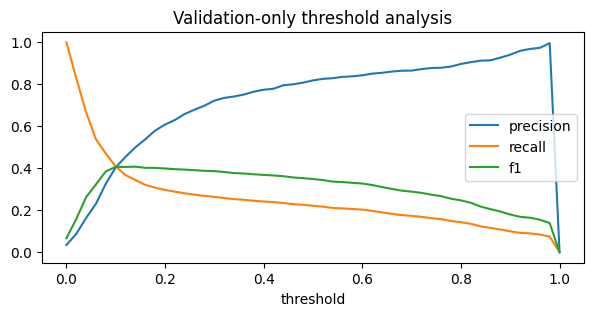

In [12]:
comparison=pd.DataFrame([{"method":r["configuration"]["method"],"seed":r["configuration"]["seed"],"AP":r["metrics"]["average_precision"],"precision":r["metrics"]["precision"],"recall":r["metrics"]["recall"],"F1":r["metrics"]["f1"]} for r in runs])
display(comparison.groupby("method").agg(["mean","std"]))
r=selected[0]
with np.load(ROOT/"artifacts"/r["id"]/"predictions.npz") as data:
    threshold_rows=[metrics(data["validation_y"],data["validation_probability"],float(t)) for t in np.linspace(0,1,51)]
thresholds=pd.DataFrame(threshold_rows)
thresholds.plot(x="threshold",y=["precision","recall","f1"],figsize=(7,3));plt.title("Validation-only threshold analysis");plt.show()


## Interpretation, explanations, and limits
Natural prevalence makes accuracy an incomplete criterion. SMOTENC may generate unrealistic combinations; weighting/oversampling can miscalibrate scores. IID bootstrap intervals do not account for dependence or drift. Integrated gradients explain sensitivity relative to a zero encoded baseline, not causality or calibrated probability contributions.

In [13]:
from ml.pipeline import infer
r=selected[0]
# Explicit missing-input demonstration using a real saved model, not a genuine transaction.
example={f:None for f in r["feature_schema"]}
assessment=infer(str(ROOT/"artifacts"/r["id"]),example,explain=True)
display({"label":"All-missing input demonstration","model":assessment["model_version"],"score":assessment["probability"],"method":assessment["explanation"]["method"],"caution":assessment["explanation"]["caution"]})


{'label': 'All-missing input demonstration',
 'model': 'ac2d51e385ed4d38bf1d766797fba69c',
 'score': 0.08366364240646362,
 'method': 'integrated_gradients_logit',
 'caution': 'Model sensitivity relative to an encoded baseline; not causal evidence or a calibrated probability decomposition.'}

## Export the same artifacts for the dashboard and paper
This regenerates the canonical CSV/JSON, curves, LaTeX tables and quantitative prose. No results are manually typed into the dashboard.

In [14]:
from scripts.export_results import export
export(ROOT)
import subprocess
subprocess.run([sys.executable,str(ROOT/"scripts/generate_paper_tables.py")],check=True)
print("Canonical export complete. Read docs/LITERATURE_MATRIX.md for verified references.")


Exported 14 saved runs; selected 5 controlled IEEE-CIS runs


Canonical export complete. Read docs/LITERATURE_MATRIX.md for verified references.


## Exploratory follow-up models
The models below are separate from the controlled ANN means. Selection uses validation AP; follow-up test reporting is exploratory because this holdout has already been inspected. Kaggle leaderboard ROC-AUC is not average precision or alert precision.

In [ ]:
exploratory = [r for r in records if not r["dataset"]["demonstration"] and not r["dataset"]["development_sample"] and r["configuration"].get("run_role")=="exploratory"]
pd.DataFrame([{ "name":r["configuration"]["name"], "validation_AP":r["validation_metrics"]["average_precision"], **{k:r["metrics"][k] for k in ["average_precision","roc_auc","precision","recall","f1","fn"]}} for r in exploratory]).sort_values("validation_AP",ascending=False)